# U01a — Llama-3.2-3B-Instruct normal/context sanity

This notebook pauses U01 method selection and tests a stronger generator under:

- context: `NO_PREV` vs `WITH_PREV`
- temporal mode: `FULL`, `PULSE16`, `SIG_EARLY75`, `STEP75`, `RECOVER`, `LINEAR75`
- 20 frozen U01 prompts

The original task prompt is **never suppressed**. Under `WITH_PREV`, the complete previous AI answer is also part of the unsuppressed prompt context. Only the newly generated self-history is attenuated.

Your explicit list contains 6 temporal modes, so the factorial is **20 × 2 × 6 = 240 generations**, not 200. This notebook preserves all six requested modes.

No text is printed initially; the first report is EOS/non-EOS only.


In [1]:
from pathlib import Path
import gc,math,hashlib
import numpy as np,pandas as pd,torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoTokenizer,AutoModelForCausalLM
from IPython.display import display

ROOT=Path.cwd().resolve()
if ROOT.name=="experiments": ROOT=ROOT.parent
if not (ROOT/"results").exists() and (ROOT.parent/"results").exists(): ROOT=ROOT.parent
assert (ROOT/"results").exists(),ROOT

U01=ROOT/"results/causal/U01_temporal_method_selection"
OUT=ROOT/"results/causal/U01a_llama32_prev_context_sanity";OUT.mkdir(parents=True,exist_ok=True)

MODEL_ID="meta-llama/Llama-3.2-3B-Instruct"
MAX_NEW_TOKENS=480
K=64
METHODS=["FULL","PULSE16","SIG_EARLY75","STEP75","RECOVER","LINEAR75"]
CONTEXT_MODES=["NO_PREV","WITH_PREV"]
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype=torch.float16 if device.type=="cuda" else torch.float32

cohort=pd.read_csv(U01/"cohort20.csv",keep_default_na=False)
assert len(cohort)==20 and cohort.source_id.nunique()==20

pair_path=ROOT/"results/causal/C02d2_fz118_ghostbuster_raid/paired_corpus.parquet"
paired=pd.read_parquet(pair_path)
assert {"source_id","text"}.issubset(paired.columns)

def raw_id(x):
    x=str(x)
    return x.split("ai__raid:",1)[1] if x.startswith("ai__raid:") else x

cohort["raw_id"]=cohort.source_id.astype(str).map(raw_id)
paired=paired.copy();paired["raw_id"]=paired.source_id.astype(str).map(raw_id)
exact=paired.drop_duplicates("source_id").set_index("source_id").text.to_dict()
rawmap=paired.drop_duplicates("raw_id").set_index("raw_id").text.to_dict()
cohort["previous_ai"]=cohort.source_id.astype(str).map(exact)
miss=cohort.previous_ai.isna()
cohort.loc[miss,"previous_ai"]=cohort.loc[miss,"raw_id"].map(rawmap)
assert cohort.previous_ai.notna().all()
cohort=cohort.drop(columns="raw_id")

print("prompts:",len(cohort))
print("methods:",METHODS)
print("contexts:",CONTEXT_MODES)
print("total generations:",len(cohort)*len(METHODS)*len(CONTEXT_MODES))
display(cohort[["case_id","source_id","domain"]])


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


prompts: 20
methods: ['FULL', 'PULSE16', 'SIG_EARLY75', 'STEP75', 'RECOVER', 'LINEAR75']
contexts: ['NO_PREV', 'WITH_PREV']
total generations: 240


,case_id,source_id,domain
0,gate_0090,ai__raid:e3945a96-7048-41d9-9e86-a84e87818986,abstracts
1,gate_0070,ai__raid:7a3b622e-1e88-48ce-98e0-2f87da5c573c,books
2,gate_0017,ai__raid:b4b807b1-fbfa-43d8-9fc3-61bd36b078ef,news
3,gate_0085,ai__raid:fa8bd0e4-3134-4d4d-83e4-4749c0bf6462,recipes
4,gate_0038,ai__raid:bf3df034-9724-4840-86cb-33eb1489b717,reddit
5,gate_0039,ai__raid:8760103e-729a-4bab-b799-5775ac2468b1,wiki
6,gate_0069,ai__raid:c7b5fc38-2bbb-4e44-bba7-dc8ac8eae773,abstracts
7,gate_0035,ai__raid:e0c2314e-b8d9-422e-af55-1498f8c4dce9,books
8,gate_0003,ai__raid:2abdd1df-30c9-4db4-bc75-08ae57b9ec93,news
9,gate_0025,ai__raid:dab3ef7f-6a54-49f9-9367-e907f0618c82,recipes


In [2]:
def norm_sigmoid(t,floor=.75,center=112,scale=18,start=64):
    if t<=start:return 1.0
    s=lambda x:1/(1+math.exp((x-center)/scale))
    return float(np.clip(floor+(1-floor)*s(t)/s(start),floor,1.0))

def lambda_full(method,t):
    if method=="FULL":return 1.0
    if t<64:return 1.0
    if method=="STEP75":return .75
    if method=="PULSE16":return 0.0 if (t-64)%16==0 else 1.0
    if method=="SIG_EARLY75":return norm_sigmoid(t,.75,112,18)
    if method=="LINEAR75":return .75 if t>=192 else 1-.25*(t-64)/128
    if method=="RECOVER":
        if t<128:return 1-.25*(t-64)/64
        if t<192:return .75
        if t<320:return .75+.15*(t-192)/128
        return .90
    raise KeyError(method)


## Load Llama 3.2 3B

The Hugging Face checkpoint is gated. If this cell returns an authorization error, authenticate the local Hugging Face environment and rerun it.


In [3]:
tok=AutoTokenizer.from_pretrained(MODEL_ID,use_fast=True)
model=AutoModelForCausalLM.from_pretrained(
    MODEL_ID,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

eos=model.generation_config.eos_token_id
if eos is None:eos=tok.eos_token_id
EOS=set(eos if isinstance(eos,(list,tuple)) else [eos])
print("loaded:",MODEL_ID)
print("EOS IDs:",EOS)


Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████| 254/254 [00:01<00:00, 172.35it/s]


loaded: meta-llama/Llama-3.2-3B-Instruct
EOS IDs: {128008, 128001, 128009}


In [4]:
def build_messages(prompt,previous_ai,context_mode):
    if context_mode=="NO_PREV":
        content=f"Original task:\n{prompt}\n\nGenerate a complete answer to the original task."
    elif context_mode=="WITH_PREV":
        content=(
            f"Original task:\n{prompt}\n\n"
            f"Previous AI answer:\n{previous_ai}\n\n"
            "Generate a fresh complete answer to the original task. "
            "Preserve the substantive content of the previous AI answer."
        )
    else: raise KeyError(context_mode)
    return [{"role":"user","content":content}]

def prompt_ids(prompt,previous_ai,context_mode):
    rendered=tok.apply_chat_template(
        build_messages(prompt,previous_ai,context_mode),
        tokenize=False,add_generation_prompt=True
    )
    return tok(rendered,return_tensors="pt",add_special_tokens=False)["input_ids"].to(device)


In [7]:
@torch.inference_mode()
def generate_one(prompt,previous_ai,context_mode,method):
    p0=prompt_ids(prompt,previous_ai,context_mode)
    p=p0[0].tolist()

    # Only materialize final-position logits.
    out=model(
        input_ids=p0,
        use_cache=True,
        logits_to_keep=1
    )
    full_logits=out.logits[:,-1,:].float()
    past=out.past_key_values

    gen=[]
    first=None
    over=0
    active=0
    sum_lam=0.

    for t in range(MAX_NEW_TOKENS):
        lam=float(lambda_full(method,t))
        sum_lam+=lam

        full_choice=int(full_logits.argmax(-1).item())

        if lam>=1-1e-12:
            nxt=full_choice
        else:
            active+=1

            # IMPORTANT:
            # entire prompt is always retained;
            # only generated self-history is capped to K.
            cap=torch.tensor(
                [p+gen[-K:]],
                device=device,
                dtype=torch.long
            )

            cap_out=model(
                input_ids=cap,
                use_cache=False,
                logits_to_keep=1
            )
            cap_logits=cap_out.logits[:,-1,:].float()

            if lam<=1e-12:
                nxt=int(cap_logits.argmax(-1).item())
            else:
                lq=torch.logaddexp(
                    F.log_softmax(full_logits,-1)+math.log(lam),
                    F.log_softmax(cap_logits,-1)+math.log1p(-lam)
                )
                nxt=int(lq.argmax(-1).item())

            del cap_out,cap_logits,cap

        if nxt!=full_choice:
            over+=1
            if first is None:
                first=t

        if nxt in EOS:
            return (
                gen,"eos",first,active,over,
                sum_lam/max(1,t+1)
            )

        gen.append(nxt)

        out=model(
            input_ids=torch.tensor([[nxt]],device=device),
            past_key_values=past,
            use_cache=True,
            logits_to_keep=1
        )
        full_logits=out.logits[:,-1,:].float()
        past=out.past_key_values

    return (
        gen,"max_tokens",first,active,over,
        sum_lam/MAX_NEW_TOKENS
    )

In [8]:
gc.collect()
torch.cuda.empty_cache()

free,total=torch.cuda.mem_get_info()
print(f"CUDA free: {free/2**30:.2f} GiB / {total/2**30:.2f} GiB")

CUDA free: 0.48 GiB / 7.62 GiB


## Run all 240 generations

The cell checkpoints after every individual generation. No generated text is displayed.


In [9]:
GEN_PATH=OUT/"generations.parquet"
gen=pd.read_parquet(GEN_PATH) if GEN_PATH.exists() else pd.DataFrame()
done=set()
if len(gen):
    done=set(zip(gen.source_id.astype(str),gen.context_mode.astype(str),gen.method.astype(str)))
rows=gen.to_dict("records") if len(gen) else []
total=len(cohort)*len(CONTEXT_MODES)*len(METHODS)
pbar=tqdm(total=total,initial=len(done),desc="U01a Llama generations")

for src in cohort.itertuples(index=False):
    for context_mode in CONTEXT_MODES:
        for method in METHODS:
            key=(str(src.source_id),context_mode,method)
            if key in done:continue
            ids,stop,first,active,over,mean_lam=generate_one(
                src.prompt,src.previous_ai,context_mode,method
            )
            text=tok.decode(ids,skip_special_tokens=True)
            rows.append({
                "case_id":src.case_id,"source_id":str(src.source_id),"domain":src.domain,
                "context_mode":context_mode,"method":method,"model_id":MODEL_ID,
                "generated_text":text,"generator_tokens":len(ids),"stop_reason":stop,
                "first_override_step":first,"active_steps":active,"override_count":over,
                "mean_lambda_full":mean_lam,
                "text_sha":hashlib.sha256(text.encode()).hexdigest()
            })
            gen=pd.DataFrame(rows);gen.to_parquet(GEN_PATH,index=False);pbar.update(1)

pbar.close()
expected=len(cohort)*len(CONTEXT_MODES)*len(METHODS)
assert len(gen)==expected,(len(gen),expected)
print("saved:",GEN_PATH)
print("completed:",len(gen),"/",expected)



U01a Llama generations:   3%|██▏                                                                      | 7/240 [09:46<5:25:08, 83.73s/it]

U01a Llama generations: 100%|███████████████████████████████████████████████████████████████████████| 240/240 [2:22:27<00:00, 36.69s/it]

saved: ../results/causal/U01a_llama32_prev_context_sanity/generations.parquet
completed: 240 / 240


## EOS results only

Stop here first. Generated text stays saved but is not printed.


In [10]:
eos_summary=(
    gen.groupby(["context_mode","method"])
    .agg(
        n=("source_id","size"),
        eos=("stop_reason",lambda x:int((x=="eos").sum())),
        non_eos=("stop_reason",lambda x:int((x!="eos").sum())),
        eos_rate=("stop_reason",lambda x:float((x=="eos").mean())),
        mean_tokens=("generator_tokens","mean"),
        median_tokens=("generator_tokens","median"),
        mean_overrides=("override_count","mean")
    ).reset_index()
)
eos_summary.to_csv(OUT/"eos_summary.csv",index=False)

print("EOS BY CONTEXT × METHOD")
display(eos_summary.sort_values(["context_mode","non_eos","method"]))

print("\nFULL ONLY")
full_summary=(
    gen[gen.method.eq("FULL")]
    .groupby("context_mode")
    .agg(
        n=("source_id","size"),
        eos=("stop_reason",lambda x:int((x=="eos").sum())),
        non_eos=("stop_reason",lambda x:int((x!="eos").sum())),
        eos_rate=("stop_reason",lambda x:float((x=="eos").mean())),
        mean_tokens=("generator_tokens","mean")
    ).reset_index()
)
display(full_summary)

print("\nNON-EOS COUNTS BY DOMAIN")
domain_fail=(
    gen[gen.stop_reason.ne("eos")]
    .groupby(["context_mode","method","domain"])
    .size().rename("non_eos").reset_index()
)
display(domain_fail)
domain_fail.to_csv(OUT/"non_eos_by_domain.csv",index=False)


EOS BY CONTEXT × METHOD


,context_mode,method,n,eos,non_eos,eos_rate,mean_tokens,median_tokens,mean_overrides
0,NO_PREV,FULL,20,15,5,0.75,369.75,346.0,0.00
1,NO_PREV,LINEAR75,20,15,5,0.75,375.20,364.5,6.10
4,NO_PREV,SIG_EARLY75,20,15,5,0.75,380.10,364.5,6.70
5,NO_PREV,STEP75,20,15,5,0.75,380.00,364.5,6.85
2,NO_PREV,PULSE16,20,14,6,0.70,390.90,385.0,3.80
3,NO_PREV,RECOVER,20,14,6,0.70,379.90,375.5,5.05
9,WITH_PREV,RECOVER,20,17,3,0.85,358.60,382.5,1.85
6,WITH_PREV,FULL,20,16,4,0.80,348.60,393.0,0.00
10,WITH_PREV,SIG_EARLY75,20,16,4,0.80,361.30,386.5,2.95
7,WITH_PREV,LINEAR75,20,15,5,0.75,359.25,378.5,2.65



FULL ONLY


,context_mode,n,eos,non_eos,eos_rate,mean_tokens
0,NO_PREV,20,15,5,0.75,369.75
1,WITH_PREV,20,16,4,0.80,348.60



NON-EOS COUNTS BY DOMAIN


,context_mode,method,domain,non_eos
0,NO_PREV,FULL,recipes,3
1,NO_PREV,FULL,wiki,2
2,NO_PREV,LINEAR75,recipes,3
3,NO_PREV,LINEAR75,wiki,2
4,NO_PREV,PULSE16,news,1
5,NO_PREV,PULSE16,recipes,3
6,NO_PREV,PULSE16,wiki,2
7,NO_PREV,RECOVER,news,1
8,NO_PREV,RECOVER,recipes,3
9,NO_PREV,RECOVER,wiki,2


In [11]:
# Print every FULL non-EOS case: original prompt + generated text.
full_fail=(
    gen[
        gen.method.eq("FULL")
        & gen.stop_reason.ne("eos")
    ]
    .merge(
        cohort[["source_id","prompt"]],
        on="source_id",
        how="left",
        validate="many_to_one"
    )
    .sort_values(["context_mode","domain","case_id"])
)

print(f"FULL non-EOS generations: {len(full_fail)}")

for r in full_fail.itertuples(index=False):
    print("\n"+"="*140)
    print(
        f"{r.context_mode} | {r.case_id} | {r.domain} | "
        f"stop={r.stop_reason} | tokens={r.generator_tokens}"
    )
    print("\nPROMPT:")
    print(r.prompt)
    print("\nGENERATED TEXT:")
    print(r.generated_text)

FULL non-EOS generations: 9

NO_PREV | gate_0018 | recipes | stop=max_tokens | tokens=480

PROMPT:
Write a recipe for "Z Bar Like Butta Zeppoles".

GENERATED TEXT:
**Z Bar Like Butta Zeppoles Recipe**

These sweet, crispy, and indulgent Zeppoles are inspired by the classic Italian doughnut, but with a twist. They're filled with a creamy, sweet, and tangy "Z Bar Like Butta" filling, reminiscent of the popular dessert from the hit TV show "Z Nation." Get ready to indulge in these delicious treats!

**Ingredients:**

For the Zeppole Dough:

* 2 cups all-purpose flour
* 2 teaspoons baking powder
* 1 teaspoon salt
* 1/4 cup granulated sugar
* 2 large eggs
* 2 tablespoons unsalted butter, melted
* 2 teaspoons vanilla extract
* Vegetable oil for frying

For the "Z Bar Like Butta" Filling:

* 1 cup heavy cream
* 1/2 cup powdered sugar
* 1/4 cup unsalted butter, softened
* 1 teaspoon vanilla extract
* 1/4 teaspoon salt
* 1/4 cup chopped pecans (optional)

**Instructions:**

1. **Make the Zeppol

All outputs are preserved in:

`results/causal/U01a_llama32_prev_context_sanity/generations.parquet`

Do not inspect text until the EOS table has been reviewed.


In [12]:
# Going forward.
MAX_NEW_TOKENS=640

# IMPORTANT: only manually confirmed pathological generations go here.
# Format: (source_id, context_mode, method)
DEGENERATE_KEYS=set()

def termination_class(r):
    key=(str(r.source_id),str(r.context_mode),str(r.method))
    if key in DEGENERATE_KEYS:
        return "degenerate"
    if r.stop_reason=="eos":
        return "eos"
    return "truncated"

gen["termination_class"]=[
    termination_class(r) for r in gen.itertuples(index=False)
]

display(
    gen.groupby(["context_mode","method","termination_class"])
       .size().rename("n").reset_index()
)

,context_mode,method,termination_class,n
0,NO_PREV,FULL,eos,15
1,NO_PREV,FULL,truncated,5
2,NO_PREV,LINEAR75,eos,15
3,NO_PREV,LINEAR75,truncated,5
4,NO_PREV,PULSE16,eos,14
5,NO_PREV,PULSE16,truncated,6
6,NO_PREV,RECOVER,eos,14
7,NO_PREV,RECOVER,truncated,6
8,NO_PREV,SIG_EARLY75,eos,15
9,NO_PREV,SIG_EARLY75,truncated,5


In [14]:
# Hard unload every possible generation-model reference before loading U scorer.
import gc, torch

for name in ["model","gmodel","smodel","out","past","full_logits","cap_logits","cap_out","p0","cap"]:
    if name in globals():
        del globals()[name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
    free,total=torch.cuda.mem_get_info()
    print(f"CUDA free after unload: {free/2**30:.2f} / {total/2**30:.2f} GiB")

SCORER="Qwen/Qwen3-0.6B-Base"

stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,
    dtype=dtype,
    low_cpu_mem_usage=True
).to(device).eval()

free,total=torch.cuda.mem_get_info()
print(f"CUDA free after scorer load: {free/2**30:.2f} / {total/2**30:.2f} GiB")

CUDA free after unload: 6.06 / 7.62 GiB


Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 2896.72it/s]


CUDA free after scorer load: 5.10 / 7.62 GiB


In [15]:
# Frozen U scorer — exact U01 protocol.
SCORER="Qwen/Qwen3-0.6B-Base"

if "model" in globals():
    del model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

stok=AutoTokenizer.from_pretrained(SCORER,use_fast=True)
smodel=AutoModelForCausalLM.from_pretrained(
    SCORER,dtype=dtype,low_cpu_mem_usage=True
).to(device).eval()

@torch.inference_mode()
def score_u128(text):
    ids=stok(str(text),add_special_tokens=False)["input_ids"]
    if len(ids)<256:
        return np.nan

    ids=ids[:256]
    pos=np.unique(np.linspace(128,255,8,dtype=int))
    loss={}

    for k in [8,32,128]:
        x=torch.tensor([ids[t-k:t] for t in pos],device=device)
        y=torch.tensor([ids[t] for t in pos],device=device)

        logits=smodel(
            input_ids=x,
            logits_to_keep=1
        ).logits[:,-1,:].float()

        ll=F.log_softmax(logits,-1)[
            torch.arange(len(y),device=device),y
        ]
        loss[k]=float((-ll).mean().cpu())

    return loss[8]-loss[128]


U_PATH=OUT/"U128_all_generations.parquet"

if U_PATH.exists():
    scored=pd.read_parquet(U_PATH)
else:
    scored=gen.copy()
    scored["U128"]=np.nan

keys=["source_id","context_mode","method"]

# Resume safely if partially scored.
for i in tqdm(scored.index[scored.U128.isna()],desc="U128"):
    scored.loc[i,"U128"]=score_u128(scored.loc[i,"generated_text"])

    if (i+1)%10==0:
        scored.to_parquet(U_PATH,index=False)

scored.to_parquet(U_PATH,index=False)

print("U128 scored:",scored.U128.notna().sum(),"/",len(scored))

U128: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 240/240 [00:24<00:00,  9.68it/s]

U128 scored: 208 / 240


In [16]:
# WITH_PREV/FULL is the single baseline for every condition.
baseline=(
    scored[
        scored.context_mode.eq("WITH_PREV")
        & scored.method.eq("FULL")
    ][["source_id","U128"]]
    .rename(columns={"U128":"U128_baseline"})
)

# 20 prompts × 2 contexts × 5 interventions = 200.
controlled=(
    scored[scored.method.ne("FULL")]
    .merge(baseline,on="source_id",how="left",validate="many_to_one")
    .copy()
)

controlled["delta_U128"]=controlled.U128-controlled.U128_baseline

# Carry our NEW definition of degeneration, rather than max-token status.
controlled["degenerate"]=[
    (str(r.source_id),str(r.context_mode),str(r.method)) in DEGENERATE_KEYS
    for r in controlled.itertuples(index=False)
]

assert len(controlled)==200,len(controlled)

print("Controlled observations:",len(controlled))
print("U-eligible:",controlled.delta_U128.notna().sum())
print("Confirmed degenerate:",controlled.degenerate.sum())

controlled.to_parquet(OUT/"controlled200_delta_U128.parquet",index=False)

Controlled observations: 200
U-eligible: 140
Confirmed degenerate: 0


In [17]:
# Conservative shortlist of possible repetition pathology.
# This is an AUDIT shortlist, not the degeneration label used by the graph.
from collections import Counter
import re

def loop_stats(text):
    words=re.findall(r"\b\w+\b",str(text).lower())
    lines=[x.strip().lower() for x in str(text).splitlines() if x.strip()]

    if len(words)>=8:
        ng=[tuple(words[i:i+8]) for i in range(len(words)-7)]
        c8=Counter(ng)
        rep8=1-len(c8)/len(ng)
        max8=max(c8.values())
    else:
        rep8=np.nan
        max8=0

    lc=Counter(lines)
    return pd.Series({
        "rep8":rep8,
        "max_8gram_repeat":max8,
        "max_line_repeat":max(lc.values()) if lc else 0
    })

audit=pd.concat(
    [controlled.reset_index(drop=True),
     controlled.generated_text.reset_index(drop=True).apply(loop_stats)],
    axis=1
)

# Intentionally conservative: just candidates for human verification.
audit["loop_candidate"]=(
    (audit.max_line_repeat>=4)
    | ((audit.max_8gram_repeat>=4)&(audit.rep8>=.20))
)

display(
    audit[audit.loop_candidate][[
        "case_id","source_id","domain","context_mode","method",
        "stop_reason","generator_tokens",
        "rep8","max_8gram_repeat","max_line_repeat"
    ]].sort_values(["domain","case_id","context_mode","method"])
)

,case_id,source_id,domain,context_mode,method,stop_reason,generator_tokens,rep8,max_8gram_repeat,max_line_repeat
174,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,NO_PREV,LINEAR75,max_tokens,480,0.003937,2.0,4.0
171,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,NO_PREV,SIG_EARLY75,max_tokens,480,0.003937,2.0,4.0
172,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,NO_PREV,STEP75,max_tokens,480,0.000000,1.0,4.0


In [18]:
# Inspect the three remaining loop-candidate outputs only.
suspect_keys=[
    ("gate_0051","NO_PREV","LINEAR75"),
    ("gate_0051","NO_PREV","SIG_EARLY75"),
    ("gate_0051","NO_PREV","STEP75"),
]

for case_id,ctx,method in suspect_keys:
    r=controlled[
        controlled.case_id.eq(case_id)
        & controlled.context_mode.eq(ctx)
        & controlled.method.eq(method)
    ].iloc[0]

    print("\n"+"="*140)
    print(
        f"{case_id} | {ctx} | {method} | "
        f"stop={r.stop_reason} | tokens={r.generator_tokens}"
    )
    print(r.generated_text)


gate_0051 | NO_PREV | LINEAR75 | stop=max_tokens | tokens=480
Blue Merle

Blue Merle is an American indie rock band from Los Angeles, California, formed in 2010. The band consists of lead vocalist and guitarist, Ryan O'Keefe, bassist, Mike O'Keefe (Ryan's brother), and drummer, Chris O'Keefe (Ryan's brother).

Background
------------

Blue Merle's music is characterized by its introspective and emotive lyrics, combined with a blend of indie rock and folk influences. The band's sound is often described as moody and atmospheric, with a strong focus on storytelling through their songs.

Discography
------------

*   **EPs:**
    *   "Blue Merle" (2011)
    *   "The Weight of Water" (2013)
    *   "The Ocean" (2015)
*   **Albums:**
    *   "The Weight of Water" (2013)
    *   "The Ocean" (2015)
    *   "The Weight of Water (Reissue)" (2016)
    *   "The Ocean (Reissue)" (2017)
    *   "The Weight of Water (Deluxe Edition)" (2018)
    *   "The Ocean (Deluxe Edition)" (2019)

Band Members
-

In [19]:
DEGENERATE_KEYS={
    ("ai__raid:9bd937c-6bbb-4405-b5ca-56920c941b48","NO_PREV","LINEAR75"),
    ("ai__raid:9bd937c-6bbb-4405-b5ca-56920c941b48","NO_PREV","SIG_EARLY75"),
    ("ai__raid:9bd937c-6bbb-4405-b5ca-56920c941b48","NO_PREV","STEP75"),
}

In [21]:
# See exact identifiers stored for gate_0051.
display(
    controlled[controlled.case_id.eq("gate_0051")][
        ["case_id","source_id","context_mode","method"]
    ]
)

print("Exact source_id reprs:")
for x in controlled.loc[
    controlled.case_id.eq("gate_0051"),"source_id"
].unique():
    print(repr(x))

,case_id,source_id,context_mode,method
170,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,NO_PREV,PULSE16
171,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,NO_PREV,SIG_EARLY75
172,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,NO_PREV,STEP75
173,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,NO_PREV,RECOVER
174,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,NO_PREV,LINEAR75
175,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,WITH_PREV,PULSE16
176,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,WITH_PREV,SIG_EARLY75
177,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,WITH_PREV,STEP75
178,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,WITH_PREV,RECOVER
179,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,WITH_PREV,LINEAR75


Exact source_id reprs:
'ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48'


In [22]:
DEGENERATE_KEYS={
    ("gate_0051","NO_PREV","LINEAR75"),
    ("gate_0051","NO_PREV","SIG_EARLY75"),
    ("gate_0051","NO_PREV","STEP75"),
}

controlled["degenerate"]=[
    (str(r.case_id),str(r.context_mode),str(r.method)) in DEGENERATE_KEYS
    for r in controlled.itertuples(index=False)
]

print("Confirmed degenerate:",controlled.degenerate.sum())

display(
    controlled[controlled.degenerate][
        ["case_id","source_id","domain","context_mode","method",
         "stop_reason","generator_tokens","delta_U128"]
    ]
)

Confirmed degenerate: 3


,case_id,source_id,domain,context_mode,method,stop_reason,generator_tokens,delta_U128
171,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,NO_PREV,SIG_EARLY75,max_tokens,480,2.971389
172,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,NO_PREV,STEP75,max_tokens,480,2.646517
174,gate_0051,ai__raid:9bbd937c-6bbb-4405-b5ca-56920c941b48,wiki,NO_PREV,LINEAR75,max_tokens,480,2.971389


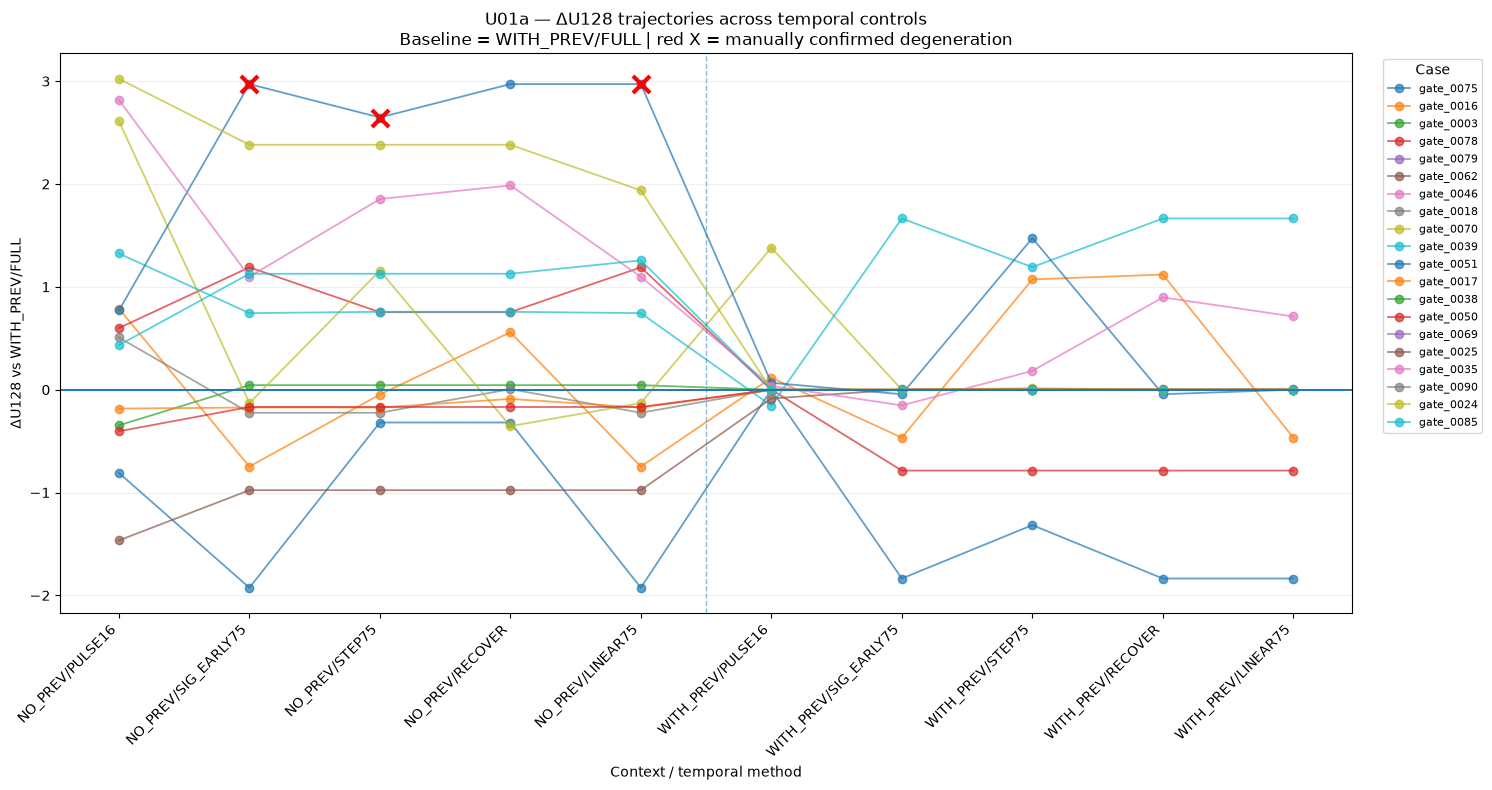

In [24]:
import matplotlib.pyplot as plt

method_order=["PULSE16","SIG_EARLY75","STEP75","RECOVER","LINEAR75"]

condition_order=[
    f"{ctx}/{m}"
    for ctx in ["NO_PREV","WITH_PREV"]
    for m in method_order
]

controlled["condition"]=[
    f"{c}/{m}"
    for c,m in zip(controlled.context_mode,controlled.method)
]

x=np.arange(len(condition_order))

fig,ax=plt.subplots(figsize=(15,8))

for sid,g in controlled.groupby("source_id"):
    g=g.set_index("condition").reindex(condition_order)
    y=g.delta_U128.to_numpy(float)

    case_id=g.case_id.dropna().iloc[0]

    ax.plot(
        x,y,
        marker="o",
        linewidth=1.3,
        alpha=.70,
        label=case_id
    )

    bad=g.degenerate.fillna(False).to_numpy(bool)&np.isfinite(y)

    if bad.any():
        ax.scatter(
            x[bad],y[bad],
            marker="x",
            s=150,
            linewidths=3,
            color="red",
            zorder=20
        )

ax.axhline(0,linewidth=1.4)
ax.axvline(4.5,linewidth=1,linestyle="--",alpha=.5)

ax.set_xticks(x)
ax.set_xticklabels(condition_order,rotation=45,ha="right")

ax.set_xlabel("Context / temporal method")
ax.set_ylabel("ΔU128 vs WITH_PREV/FULL")

ax.set_title(
    "U01a — ΔU128 trajectories across temporal controls\n"
    "Baseline = WITH_PREV/FULL | red X = manually confirmed degeneration"
)

ax.grid(axis="y",alpha=.2)

ax.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    fontsize=8,
    title="Case"
)

fig.tight_layout()

fig.savefig(
    OUT/"U01a_deltaU_spaghetti.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    OUT/"U01a_deltaU_spaghetti.pdf",
    bbox_inches="tight"
)

plt.show()

In [25]:
# Fixed per-case OG baseline: previous/original AI answer.
og=cohort[["case_id","source_id","domain","previous_ai"]].copy()

OG_PATH=OUT/"OG_U128.parquet"

if OG_PATH.exists():
    og=pd.read_parquet(OG_PATH)
else:
    og["U128_OG"]=np.nan

for i in tqdm(og.index[og.U128_OG.isna()],desc="OG U128"):
    og.loc[i,"U128_OG"]=score_u128(og.loc[i,"previous_ai"])

og.to_parquet(OG_PATH,index=False)

display(
    og[["case_id","domain","U128_OG"]]
)

OG U128: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 20/20 [00:01<00:00, 13.06it/s]


,case_id,domain,U128_OG
0,gate_0090,abstracts,NaN
1,gate_0070,books,1.801584
2,gate_0017,news,1.682802
3,gate_0085,recipes,1.145910
4,gate_0038,reddit,NaN
5,gate_0039,wiki,NaN
6,gate_0069,abstracts,NaN
7,gate_0035,books,1.762933
8,gate_0003,news,0.663992
9,gate_0025,recipes,1.436598


In [26]:
# Every generated condition relative to its fixed original AI text.
all_delta=(
    scored
    .merge(
        og[["source_id","U128_OG"]],
        on="source_id",
        how="left",
        validate="many_to_one"
    )
    .copy()
)

all_delta["delta_U128"]=all_delta.U128-all_delta.U128_OG

# Manual degeneration labels: only the 3 confirmed cases.
all_delta["degenerate"]=[
    (str(r.case_id),str(r.context_mode),str(r.method)) in DEGENERATE_KEYS
    for r in all_delta.itertuples(index=False)
]

print("Total generations:",len(all_delta))
print("U-eligible:",all_delta.delta_U128.notna().sum())
print("Confirmed degenerate:",all_delta.degenerate.sum())

Total generations: 240
U-eligible: 162
Confirmed degenerate: 3


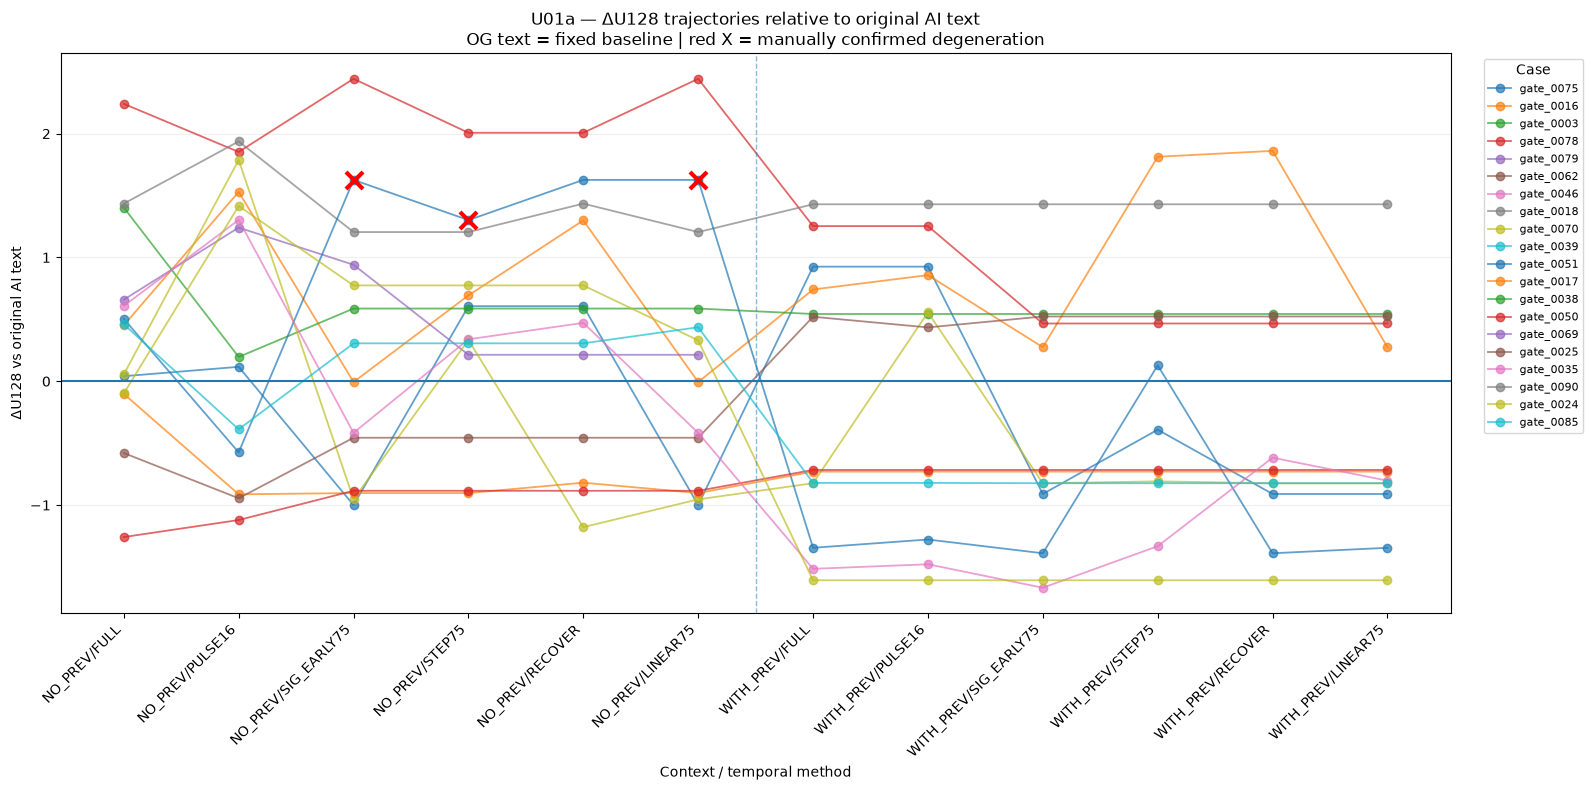

In [27]:
method_order=[
    "FULL",
    "PULSE16",
    "SIG_EARLY75",
    "STEP75",
    "RECOVER",
    "LINEAR75"
]

condition_order=[
    f"{ctx}/{m}"
    for ctx in ["NO_PREV","WITH_PREV"]
    for m in method_order
]

all_delta["condition"]=[
    f"{c}/{m}"
    for c,m in zip(all_delta.context_mode,all_delta.method)
]

x=np.arange(len(condition_order))

fig,ax=plt.subplots(figsize=(16,8))

for sid,g in all_delta.groupby("source_id"):
    g=g.set_index("condition").reindex(condition_order)
    y=g.delta_U128.to_numpy(float)

    case_id=g.case_id.dropna().iloc[0]

    ax.plot(
        x,y,
        marker="o",
        linewidth=1.3,
        alpha=.70,
        label=case_id
    )

    # Red X ONLY for manually confirmed degeneration.
    bad=g.degenerate.fillna(False).to_numpy(bool)&np.isfinite(y)

    if bad.any():
        ax.scatter(
            x[bad],y[bad],
            marker="x",
            s=150,
            linewidths=3,
            color="red",
            zorder=20
        )

# OG text is the fixed zero baseline.
ax.axhline(0,linewidth=1.5)

# Separate NO_PREV and WITH_PREV halves.
ax.axvline(5.5,linewidth=1,linestyle="--",alpha=.5)

ax.set_xticks(x)
ax.set_xticklabels(condition_order,rotation=45,ha="right")

ax.set_xlabel("Context / temporal method")
ax.set_ylabel("ΔU128 vs original AI text")

ax.set_title(
    "U01a — ΔU128 trajectories relative to original AI text\n"
    "OG text = fixed baseline | red X = manually confirmed degeneration"
)

ax.grid(axis="y",alpha=.2)

ax.legend(
    bbox_to_anchor=(1.02,1),
    loc="upper left",
    fontsize=8,
    title="Case"
)

fig.tight_layout()

fig.savefig(
    OUT/"U01a_deltaU_vs_OG_spaghetti.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    OUT/"U01a_deltaU_vs_OG_spaghetti.pdf",
    bbox_inches="tight"
)

plt.show()

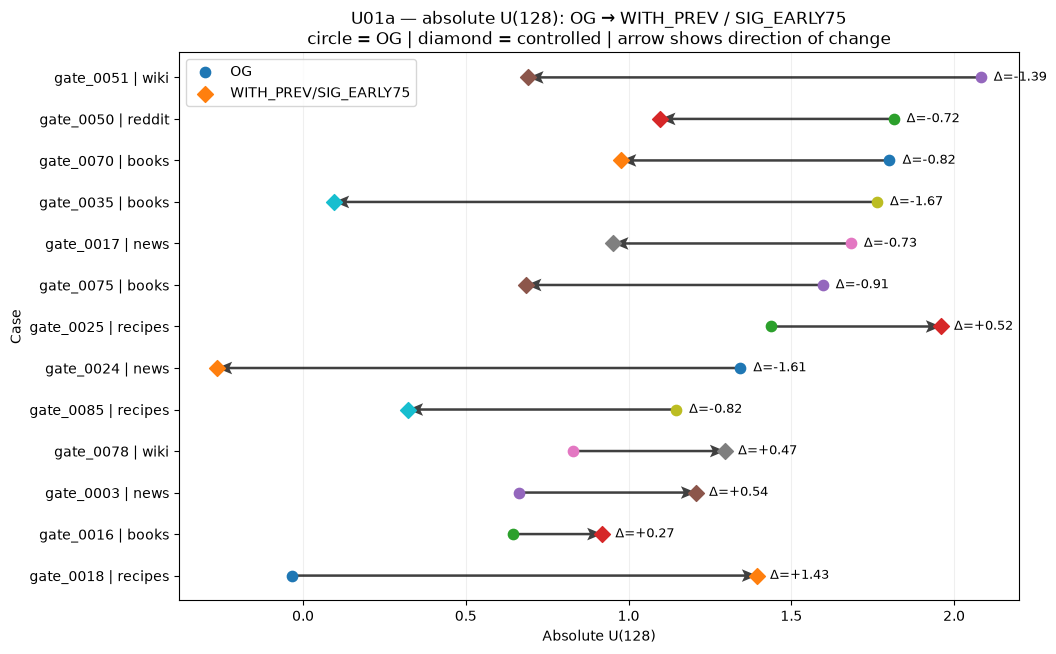

,case_id,domain,U128_OG,U128,delta_U128,degenerate
9,gate_0035,books,1.762933,0.095253,-1.667681,False
5,gate_0024,news,1.343158,-0.264256,-1.607414,False
12,gate_0051,wiki,2.081727,0.692429,-1.389298,False
7,gate_0075,books,1.596251,0.685826,-0.910425,False
10,gate_0070,books,1.801584,0.977297,-0.824287,False
4,gate_0085,recipes,1.145910,0.322206,-0.823704,False
8,gate_0017,news,1.682802,0.953252,-0.729549,False
11,gate_0050,reddit,1.814070,1.097706,-0.716363,False
1,gate_0016,books,0.644437,0.919270,0.274832,False
3,gate_0078,wiki,0.829881,1.296381,0.466500,False


In [29]:
# Robust absolute U(128): OG -> WITH_PREV / SIG_EARLY75
# Uses quiver instead of FancyArrowPatch to avoid StopIteration.

target_method="SIG_EARLY75"
target_context="WITH_PREV"

plot_df=(
    all_delta[
        all_delta.context_mode.eq(target_context)
        & all_delta.method.eq(target_method)
    ][
        ["case_id","source_id","domain",
         "U128","U128_OG","delta_U128","degenerate"]
    ]
    .drop_duplicates("source_id")
    .dropna(subset=["U128","U128_OG"])
    .copy()
)

plot_df["label"]=plot_df.case_id+" | "+plot_df.domain
plot_df=plot_df.sort_values("U128_OG").reset_index(drop=True)

fig,ax=plt.subplots(figsize=(12,max(6,.45*len(plot_df)+1)))
y=np.arange(len(plot_df))

for i,r in plot_df.iterrows():
    x0=float(r.U128_OG)
    x1=float(r.U128)
    dx=x1-x0

    # OG endpoint
    ax.scatter(
        x0,i,
        s=55,marker="o",zorder=4,
        label="OG" if i==0 else None
    )

    # Controlled endpoint
    ax.scatter(
        x1,i,
        s=65,marker="D",zorder=5,
        label="WITH_PREV/SIG_EARLY75" if i==0 else None
    )

    # Arrow if movement is nonzero; short line if effectively identical.
    if abs(dx)>1e-6:
        ax.quiver(
            x0,i,dx,0,
            angles="xy",
            scale_units="xy",
            scale=1,
            width=.003,
            headwidth=5,
            headlength=6,
            headaxislength=5,
            alpha=.75,
            zorder=3
        )
    else:
        ax.plot([x0-.015,x0+.015],[i,i],linewidth=1.5,alpha=.75)

    # Δ label
    ax.text(
        max(x0,x1)+.04,
        i,
        f"Δ={dx:+.2f}",
        va="center",
        fontsize=9
    )

    if bool(r.degenerate):
        ax.scatter(
            x1,i,
            marker="x",
            s=140,
            linewidths=2.5,
            color="red",
            zorder=10
        )

ax.set_yticks(y)
ax.set_yticklabels(plot_df.label)
ax.set_xlabel("Absolute U(128)")
ax.set_ylabel("Case")
ax.set_title(
    "U01a — absolute U(128): OG → WITH_PREV / SIG_EARLY75\n"
    "circle = OG | diamond = controlled | arrow shows direction of change"
)
ax.grid(axis="x",alpha=.2)
ax.legend()

plt.subplots_adjust(left=.22,right=.92,top=.90,bottom=.10)

fig.savefig(
    OUT/"U01a_OG_to_WITHPREV_SIGEARLY75_absolute_U128.png",
    dpi=300,bbox_inches="tight"
)
fig.savefig(
    OUT/"U01a_OG_to_WITHPREV_SIGEARLY75_absolute_U128.pdf",
    bbox_inches="tight"
)

plt.show()

display(
    plot_df[
        ["case_id","domain","U128_OG","U128","delta_U128","degenerate"]
    ].sort_values("delta_U128")
)